# Visualizations for the README

This notebook builds the charts shown in the project's `README.md` and saves them to the `images/` folder. Each chart carries one key finding of the analysis; the full analysis and all statistical tests are in [`students_performance_analysis.ipynb`](students_performance_analysis.ipynb).

The data are cleaned exactly as in the analysis notebook: the 16 students with `G3 = 0` or `G1 = 0` are removed, leaving 633 students.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np
from pathlib import Path

# Data visualization
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Statistics and modeling
from statsmodels.stats.proportion import proportion_confint
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import roc_auc_score

## Style

All charts share one style: a light surface, recessive hairline grid and axes, and a colorblind-safe palette (blue for passing students, orange for failing ones). Text never uses the series colors.

In [2]:
SURFACE = '#fcfcfb'
TEXT_PRIMARY = '#0b0b0b'
TEXT_SECONDARY = '#52514e'
GRID = '#e4e3df'
BLUE = '#2a78d6'    # passed / main series
ORANGE = '#eb6834'  # failed

plt.rcParams.update({
	'figure.facecolor': SURFACE,
	'axes.facecolor': SURFACE,
	'savefig.facecolor': SURFACE,
	'axes.edgecolor': GRID,
	'axes.linewidth': 0.8,
	'axes.spines.top': False,
	'axes.spines.right': False,
	'axes.grid': True,
	'axes.axisbelow': True,
	'grid.color': GRID,
	'grid.linewidth': 0.8,
	'axes.labelcolor': TEXT_SECONDARY,
	'axes.labelsize': 11,
	'xtick.color': TEXT_SECONDARY,
	'ytick.color': TEXT_SECONDARY,
	'xtick.labelsize': 10,
	'ytick.labelsize': 10,
	'legend.frameon': False,
	'legend.fontsize': 10,
	'font.size': 11,
})

IMAGES_DIR = Path('images')
IMAGES_DIR.mkdir(exist_ok=True)


def add_titles(ax, title, subtitle):
	"""Left-aligned title with a one-line subtitle underneath."""
	ax.set_title(title, loc='left', fontsize=15, fontweight='bold', color=TEXT_PRIMARY, pad=30)
	ax.text(0, 1.035, subtitle, transform=ax.transAxes, fontsize=11, color=TEXT_SECONDARY, va='bottom')


def save(fig, name):
	fig.savefig(IMAGES_DIR / name, dpi=150, bbox_inches='tight')

## Data

In [3]:
data = pd.read_csv('./docs/data/student-por.csv')

# Same cleaning as in the analysis notebook: drop students with G3 = 0 (missed the final exam) or G1 = 0
data = data[(data['G3'] != 0) & (data['G1'] != 0)].copy()

data['Passed'] = data['G3'] >= 10
data['AvgMidGrade'] = (data['G1'] + data['G2']) / 2
print(f'Students: {len(data)}, failing: {(~data["Passed"]).sum()} ({(~data["Passed"]).mean():.1%})')

Students: 633, failing: 85 (13.4%)


## 1. Mid-year grades predict the final grade

Each dot is a student. Grades are whole numbers, so many students share the same position; a small random jitter (fixed seed) spreads them out so that dense areas stay visible. The line is the least-squares fit of the final grade on the average mid-year grade.

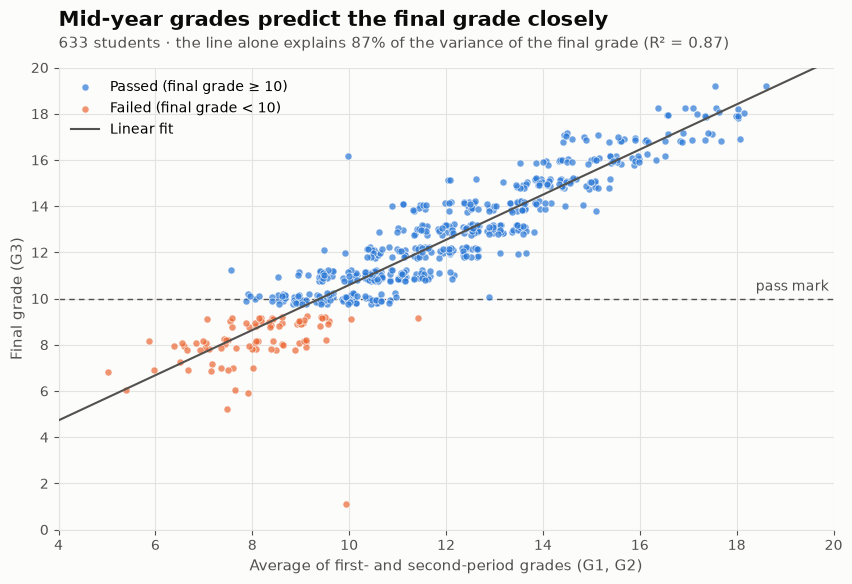

In [4]:
rng = np.random.default_rng(0)
x_jitter = data['AvgMidGrade'] + rng.uniform(-0.18, 0.18, len(data))
y_jitter = data['G3'] + rng.uniform(-0.25, 0.25, len(data))

slope, intercept = np.polyfit(data['AvgMidGrade'], data['G3'], 1)
r2 = np.corrcoef(data['AvgMidGrade'], data['G3'])[0, 1] ** 2

fig, ax = plt.subplots(figsize=(10, 6))
for passed, color, label in [(True, BLUE, 'Passed (final grade ≥ 10)'), (False, ORANGE, 'Failed (final grade < 10)')]:
	mask = data['Passed'] == passed
	ax.scatter(
		x_jitter[mask], y_jitter[mask],
		s=26, color=color, alpha=0.7, edgecolor=SURFACE, linewidth=0.6, label=label, zorder=3
	)

x_line = np.array([4, 20])
ax.plot(x_line, intercept + slope * x_line, color=TEXT_SECONDARY, linewidth=1.5, zorder=4, label='Linear fit')
ax.axhline(10, color=TEXT_SECONDARY, linewidth=1, linestyle=(0, (4, 3)), zorder=2)
ax.text(19.9, 10.2, 'pass mark', ha='right', va='bottom', fontsize=10, color=TEXT_SECONDARY)

ax.set_xlim(4, 20)
ax.set_ylim(0, 20)
ax.set_xticks(range(4, 21, 2))
ax.set_yticks(range(0, 21, 2))
ax.set_xlabel('Average of first- and second-period grades (G1, G2)')
ax.set_ylabel('Final grade (G3)')
ax.legend(loc='upper left')
add_titles(
	ax,
	'Mid-year grades predict the final grade closely',
	f'{len(data)} students · the line alone explains {r2:.0%} of the variance of the final grade (R² = {r2:.2f})'
)

save(fig, 'midyear_vs_final_grade.png')
plt.show()

## 2. Past failures and the risk of failing

The share of students who fail the course, by the number of past class failures. The thin vertical lines are 95% Wilson confidence intervals: the groups with 2 and 3 past failures are small, so their exact rates are uncertain.

In [5]:
fail_by_failures = (
	data.assign(Failed=~data['Passed'])
	.groupby('failures')['Failed']
	.agg(failed='sum', students='size')
)
fail_by_failures['rate'] = fail_by_failures['failed'] / fail_by_failures['students']
ci_low, ci_high = proportion_confint(
	fail_by_failures['failed'], fail_by_failures['students'], alpha=0.05, method='wilson'
)
fail_by_failures['ci_low'] = ci_low
fail_by_failures['ci_high'] = ci_high
fail_by_failures

,failed,students,rate,ci_low,ci_high
failures,,,,,
0,45,542,0.083026,0.062628,0.109293
1,25,63,0.396825,0.285319,0.520191
2,7,15,0.466667,0.248095,0.698830
3,8,13,0.615385,0.355229,0.822903


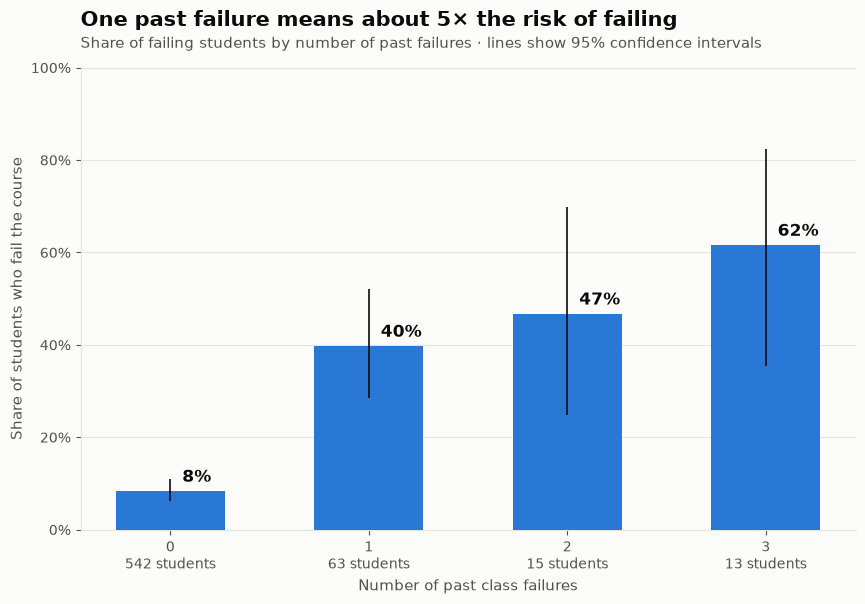

In [6]:
risk_ratio = fail_by_failures.loc[1, 'rate'] / fail_by_failures.loc[0, 'rate']
positions = np.arange(len(fail_by_failures))

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(positions, fail_by_failures['rate'], width=0.55, color=BLUE, zorder=3)
ax.vlines(
	positions, fail_by_failures['ci_low'], fail_by_failures['ci_high'],
	color=TEXT_PRIMARY, linewidth=1.2, zorder=4
)
for pos, (rate, high) in zip(positions, fail_by_failures[['rate', 'ci_high']].values):
	ax.text(pos + 0.06, rate + 0.012, f'{rate:.0%}', ha='left', va='bottom', fontsize=12, fontweight='bold', color=TEXT_PRIMARY)

ax.set_xticks(
	positions,
	[f'{f}\n{n} students' for f, n in zip(fail_by_failures.index, fail_by_failures['students'])]
)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis='x', visible=False)
ax.set_xlabel('Number of past class failures')
ax.set_ylabel('Share of students who fail the course')
add_titles(
	ax,
	f'One past failure means about {risk_ratio:.0f}× the risk of failing',
	'Share of failing students by number of past failures · lines show 95% confidence intervals'
)

save(fig, 'failure_rate_by_past_failures.png')
plt.show()

## 3. Early warning before any grades exist

Can students at risk be identified at the start of the year, before any grades exist? A linear regression predicts each student's final grade from all non-grade features. The predictions are *out-of-sample*: each student's prediction comes from a model trained on the other folds of a 5-fold cross-validation, so no student is scored by a model that has seen them.

Students are then ranked from the lowest to the highest predicted grade. The curve shows which share of all failing students is found if a school flags a given share of the highest-risk students; the diagonal is what random selection would achieve.

In [7]:
X = pd.get_dummies(
	data.drop(columns=['G1', 'G2', 'G3', 'Passed', 'AvgMidGrade']),
	drop_first=True
)
predicted_grade = cross_val_predict(
	LinearRegression(), X, data['G3'], cv=KFold(n_splits=5, shuffle=True, random_state=0)
)

failed = (~data['Passed']).to_numpy()
auc = roc_auc_score(failed, -predicted_grade)

# Cumulative share of failing students found when flagging the k lowest predicted grades
order = np.argsort(predicted_grade)
flagged_share = np.arange(1, len(order) + 1) / len(order)
caught_share = np.cumsum(failed[order]) / failed.sum()

flag_20 = int(round(0.2 * len(order)))
caught_20 = caught_share[flag_20 - 1]
print(f'Out-of-sample AUC: {auc:.3f}')
print(f'Flagging the {flag_20} highest-risk students (20%) finds {caught_20:.0%} of all failing students')

Out-of-sample AUC: 0.827
Flagging the 127 highest-risk students (20%) finds 56% of all failing students


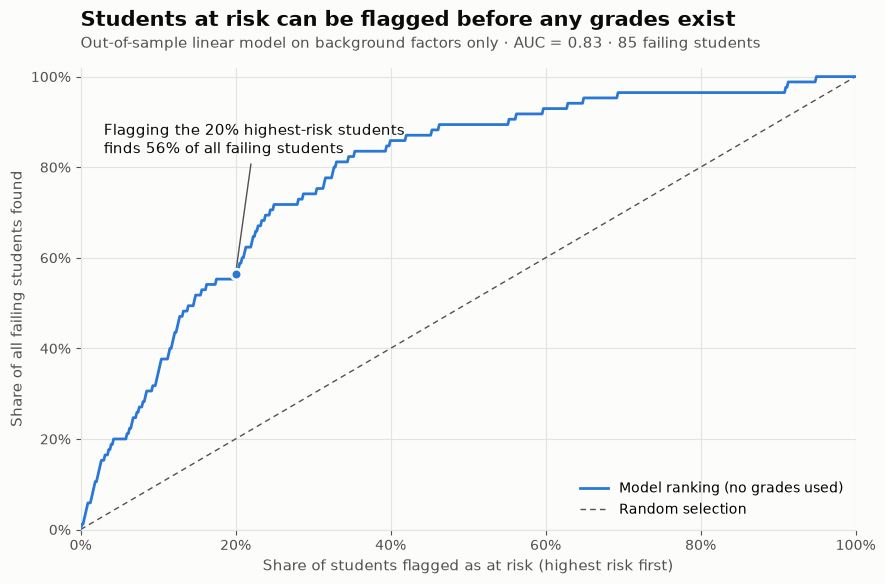

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(
	np.concatenate([[0], flagged_share]), np.concatenate([[0], caught_share]),
	color=BLUE, linewidth=2, zorder=3, label='Model ranking (no grades used)'
)
ax.plot([0, 1], [0, 1], color=TEXT_SECONDARY, linewidth=1, linestyle=(0, (4, 3)), zorder=2, label='Random selection')

ax.scatter([0.2], [caught_20], s=60, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=4)
ax.annotate(
	f'Flagging the 20% highest-risk students\nfinds {caught_20:.0%} of all failing students',
	xy=(0.2, caught_20), xytext=(0.03, 0.86),
	fontsize=11, color=TEXT_PRIMARY, va='center',
	arrowprops={'arrowstyle': '-', 'color': TEXT_SECONDARY, 'linewidth': 1},
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel('Share of students flagged as at risk (highest risk first)')
ax.set_ylabel('Share of all failing students found')
ax.legend(loc='lower right')
add_titles(
	ax,
	'Students at risk can be flagged before any grades exist',
	f'Out-of-sample linear model on background factors only · AUC = {auc:.2f} · {failed.sum()} failing students'
)

save(fig, 'early_warning_gains.png')
plt.show()